# 04 · Clean returns and rolling windows

**Owner:** Rishi · **Week 2** · Data pipeline · Code: `src/returns.py`, `src/windows.py`, tests in `tests/`

**Goal:** turn the raw S&P 500 prices into one clean, analysis-ready returns table that every feature (network, clustering, anomaly detection) starts from, plus one shared rolling-window function so nobody re-implements windows differently.

**Before running:** `data/processed/sp500_close.parquet` and `sp500_membership.parquet` must exist (run `python scripts/download_sp500_prices.py`, or copy the team's shared `data/processed/` folder).

**Produces** (in `data/processed/`):

| File | What it is |
|---|---|
| `returns_daily.parquet` | Daily simple returns, dates x tickers, member days only, cleaned |
| `returns_market.parquet` | `^GSPC` and `SPY` returns, equal-weighted member return, number of stocks with a return |
| `returns_quality.csv` | Every return that was removed or flagged, with the reason |
| `returns_summary.csv` | Counts used in `docs/data_dictionary.md` |
| `features/connectedness_60d.parquet` | Average correlation, PC1 share and absorption ratio every 5 trading days, 2005 onward |

Cleaning rules are explained in `src/returns.py` and `docs/data_dictionary.md`.

In [1]:
%matplotlib inline
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
from src import returns as rt
from src import windows as wn

PROC = ROOT / "data" / "processed"
close = pd.read_parquet(PROC / "sp500_close.parquet")
membership = pd.read_parquet(PROC / "sp500_membership.parquet")
episodes = pd.read_csv(ROOT / "docs" / "stress_periods.csv", parse_dates=["start", "end"])
print(f"Prices: {close.shape[0]} days x {close.shape[1]} series, {close.index[0].date()} to {close.index[-1].date()}")
print(f"Membership: {membership.shape[1]} tickers")

def shade(ax):
    for _, ep in episodes.iterrows():
        ax.axvspan(ep["start"], ep["end"], color="tab:red", alpha=0.12, lw=0)

Prices: 5490 days x 696 series, 2005-01-03 to 2026-10-28
Membership: 977 tickers


## 1. Build and save the clean returns

In [2]:
res = rt.clean_returns(close, membership)
paths = rt.save(res)
print("Saved:", [p.name for p in paths])
display(res.summary.to_frame("count"))
share = res.summary["member_days_with_return"] / res.summary["member_days"]
print(f"Member-days with a usable return: {share:.1%}")

Saved: ['returns_daily.parquet', 'returns_market.parquet', 'returns_quality.csv', 'returns_summary.csv']


,count
member_days,2750299
member_days_with_price,2124241
member_days_with_return,2119862
returns_nan_after_gap,289
stale_removed,1770
spike_removed,12
large_moves_kept,66
override_rows_applied,11
tickers_to_review_repeated_jumps,5


Member-days with a usable return: 77.1%


## 2. What the cleaning removed or flagged

* **spike_removed:** a one-day move above 40% that came back within 3 days (a data error).
* **stale_removed:** 5+ identical closes in a row (a dead quote).
* **large_move_kept:** a move above 40% that did not reverse, so it is treated as real.
* **repeated_jumps_review:** a ticker with 3+ flagged moves within a year. Likely a reused symbol; **check these by hand** and add a `drop` row to `docs/return_overrides.csv` if the prices are wrong.
* **override_keep / override_drop:** decisions from `docs/return_overrides.csv`.

In [3]:
q = res.quality
display(q.groupby("reason").agg(rows=("ticker", "size"), tickers=("ticker", "nunique")))

review = q[q["reason"] == "repeated_jumps_review"]
print("Tickers to review by hand (repeated large jumps):",
      sorted(review["ticker"].unique()) if len(review) else "none")

print("\nLargest real moves kept (top 15 by size):")
kept = q[q["reason"] == "large_move_kept"].assign(abs_ret=lambda d: d["raw_return"].abs())
display(kept.sort_values("abs_ret", ascending=False).head(15)[["date", "ticker", "raw_return"]])

print("Spikes removed (first 15):")
display(q[q["reason"] == "spike_removed"].head(15)[["date", "ticker", "raw_return"]])

,rows,tickers
reason,,
large_move_kept,66,41
override_drop,2794,3
override_keep,8,8
repeated_jumps_review,14,5
spike_removed,12,2
stale_removed,1770,5


Tickers to review by hand (repeated large jumps): ['AIG', 'CBRE', 'FITB', 'GNW', 'HIG']

Largest real moves kept (top 15 by size):


,date,ticker,raw_return
4663,2026-08-19,MRNA,1.769695
2017,2008-12-05,HIG,1.023579
1859,2008-09-08,FNMA,-0.896307
1998,2008-11-24,GNW,0.888889
1923,2008-10-13,MS,0.869835
1858,2008-09-08,FMCC,-0.827451
1920,2008-10-13,GNW,0.805714
1879,2008-09-18,MTG,0.746323
1901,2008-09-30,GNW,0.722000
1884,2008-09-19,GNW,0.666667


Spikes removed (first 15):


,date,ticker,raw_return
1004,2006-12-28,EP,0.437500
1006,2006-12-29,EP,-0.304348
1009,2007-01-04,CPWR,0.481481
1011,2007-01-05,CPWR,-0.375000
1765,2008-07-03,CPWR,0.600000
1767,2008-07-07,CPWR,-0.375000
2242,2009-05-06,EP,-0.411765
2244,2009-05-07,EP,0.700000
2391,2009-08-19,CPWR,0.666667
2393,2009-08-20,CPWR,-0.400000


In [4]:
# Which stocks each rule touched, with date ranges (check these by hand)
by_ticker = (q[q["reason"].isin(["stale_removed", "spike_removed", "repeated_jumps_review"])]
             .groupby(["reason", "ticker"])
             .agg(rows=("date", "size"), first=("date", "min"), last=("date", "max"),
                  biggest_move=("raw_return", lambda s: s.loc[s.abs().idxmax()] if s.notna().any() else np.nan)))
display(by_ticker)

rows      first       last  biggest_move
reason                ticker                                          
repeated_jumps_review AIG        4 2008-09-19 2009-08-05      0.660000
                      CBRE       1 2009-03-25 2009-03-25      0.640000
                      FITB       1 2009-05-08 2009-05-08      0.586917
                      GNW        7 2008-10-13 2009-03-10      0.888889
                      HIG        1 2008-12-05 2008-12-05      1.023579
spike_removed         CPWR       6 2007-01-04 2009-08-20      0.666667
                      EP         6 2006-12-28 2010-11-24      0.700000
stale_removed         AMCR       2 2019-06-07 2019-06-10      0.000000
                      CPWR     961 2006-12-05 2011-12-30      0.000000
                      EP       681 2005-01-04 2012-05-24      0.000000
                      PARA      48 2022-03-21 2023-08-18      0.000000
                      SII       78 2010-02-26 2010-08-23      0.000000

## 3. Coverage over time and a sanity check against the index

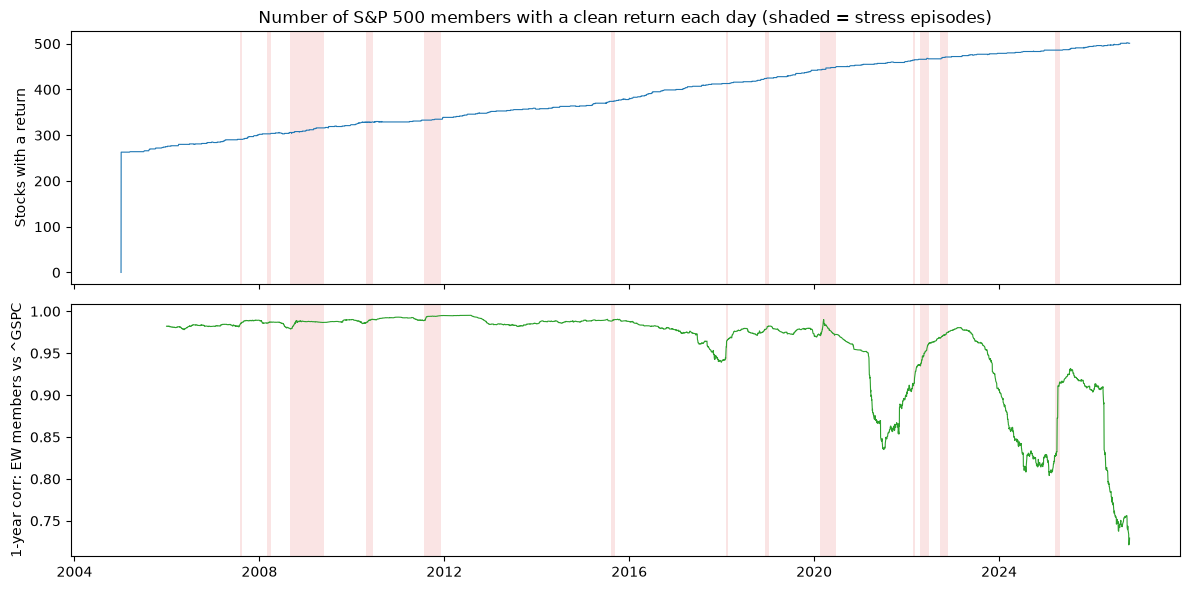

Daily-return correlation, equal-weighted members vs ^GSPC, full period: 0.965
Lowest 1-year rolling correlation: 0.721 (year ending 2026-10-22)


In [5]:
m = res.market
fig, axes = plt.subplots(2, 1, figsize=(12, 6), sharex=True)
axes[0].plot(m.index, m["n_returns"], lw=0.8)
axes[0].set_ylabel("Stocks with a return")
axes[0].set_title("Number of S&P 500 members with a clean return each day (shaded = stress episodes)")
roll = m["ew_member_ret"].rolling(250).corr(m["^GSPC_ret"])
axes[1].plot(roll.index, roll, lw=0.8, color="tab:green")
axes[1].set_ylabel("1-year corr: EW members vs ^GSPC")
for ax in axes:
    shade(ax)
plt.tight_layout(); plt.show()

print(f"Daily-return correlation, equal-weighted members vs ^GSPC, full period: "
      f"{m['ew_member_ret'].corr(m['^GSPC_ret']):.3f}")
print(f"Lowest 1-year rolling correlation: {roll.min():.3f} (year ending {roll.idxmin().date()})")

## 4. Rolling windows: connectedness over the full history

`wn.connectedness` uses trailing 60-day windows every 5 trading days, with only stocks that have a return on every day of the window. A value dated *t* uses data up to *t* only, so it can be used as a forecasting feature (`tests/` checks this: changing future returns never changes past values).

1086 windows, 2005-04-06 to 2026-10-28; saved features/connectedness_60d.parquet


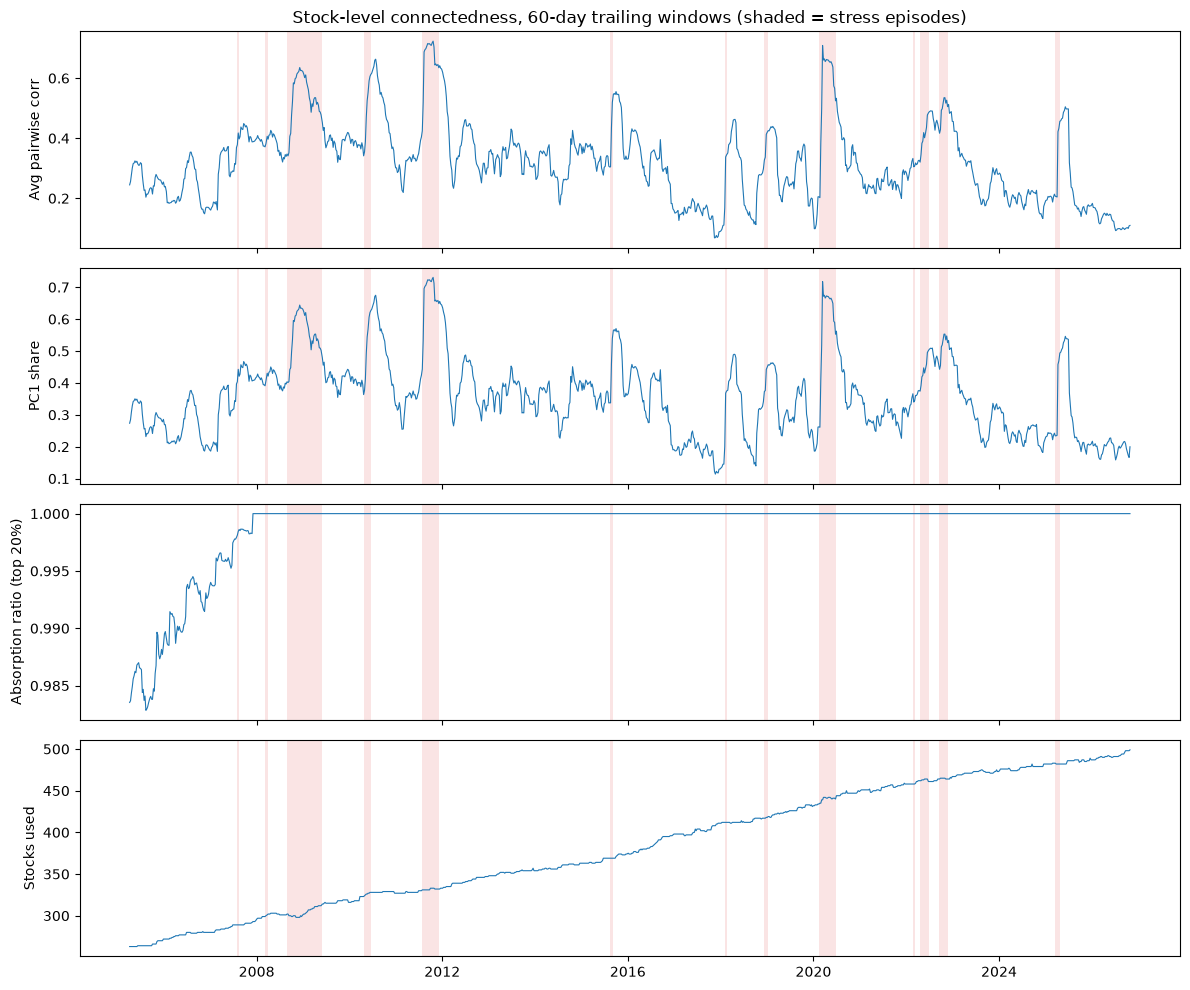

In [6]:
conn = wn.connectedness(res.returns)            # window=60, step=5, min_stocks=100
out = PROC / "features"
out.mkdir(exist_ok=True)
conn.to_parquet(out / "connectedness_60d.parquet")
print(f"{len(conn)} windows, {conn.index[0].date()} to {conn.index[-1].date()}; saved features/connectedness_60d.parquet")

fig, axes = plt.subplots(4, 1, figsize=(12, 10), sharex=True)
for ax, col, lab in zip(axes, ["avg_corr", "pc1_share", "absorption", "n_stocks"],
                        ["Avg pairwise corr", "PC1 share", "Absorption ratio (top 20%)", "Stocks used"]):
    ax.plot(conn.index, conn[col], lw=0.8)
    ax.set_ylabel(lab)
    shade(ax)
axes[0].set_title("Stock-level connectedness, 60-day trailing windows (shaded = stress episodes)")
plt.tight_layout(); plt.show()

### 4b. Cross-check with the EDA notebooks

The EDAs computed the same measures inside each notebook. The numbers will not match exactly: the window end dates fall on different days (each EDA started its windows at its own warm-up date), and the cleaning here also removes stale prices and spikes. They should be close. A large gap would point to a bug.

In [7]:
checks = {
    "2008: peak avg corr (EDA: 2008-12-02)": ("2007-01-01", "2009-12-31"),
    "2011: Jan-Jun mean (EDA: 0.310)": ("2011-01-01", "2011-06-30"),
    "2011: Sep-Oct mean (EDA: 0.715)": ("2011-09-01", "2011-10-31"),
    "2020: crash window mean (EDA: about 0.56)": ("2020-02-20", "2020-03-31"),
    "2022: Nov-Dec mean (EDA: 0.503)": ("2022-11-01", "2022-12-31"),
}
rows = []
for name, (a, b) in checks.items():
    s = conn.loc[a:b, "avg_corr"]
    rows.append({"check": name, "mean": round(s.mean(), 3), "max": round(s.max(), 3), "max date": s.idxmax().date()})
display(pd.DataFrame(rows).set_index("check"))

,mean,max,max date
check,,,
2008: peak avg corr (EDA: 2008-12-02),0.407,0.635,2008-12-05
2011: Jan-Jun mean (EDA: 0.310),0.309,0.349,2011-06-29
2011: Sep-Oct mean (EDA: 0.715),0.713,0.723,2011-10-21
2020: crash window mean (EDA: about 0.56),0.520,0.709,2020-03-13
2022: Nov-Dec mean (EDA: 0.503),0.501,0.535,2022-11-01


## 5. For the network prototype (Brandon): one correlation matrix

`wn.correlation_at(returns, date)` gives the stocks x stocks correlation matrix for the 60-day window ending on that date. Threshold it to get a network. Below: one calm date and one stress date.

2006-06-30: 280 stocks, mean corr 0.323, network density at corr > 0.5: 12.7%
2008-10-31: 299 stocks, mean corr 0.597, network density at corr > 0.5: 78.1%


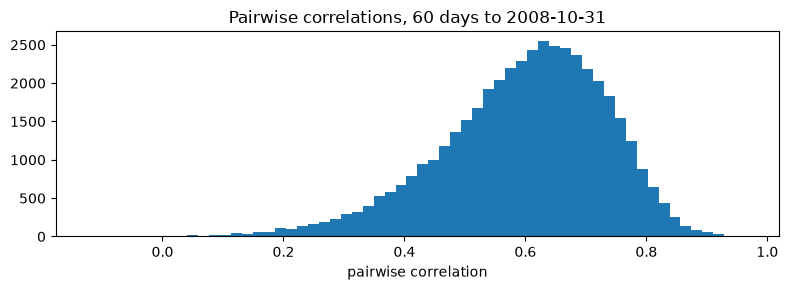

In [8]:
for d in ["2006-06-30", "2008-10-31"]:
    c = wn.correlation_at(res.returns, d)
    upper = c.to_numpy()[np.triu_indices(len(c), k=1)]
    density = (upper > 0.5).mean()
    print(f"{d}: {len(c)} stocks, mean corr {upper.mean():.3f}, network density at corr > 0.5: {density:.1%}")

c = wn.correlation_at(res.returns, "2008-10-31")
fig, ax = plt.subplots(figsize=(8, 3))
ax.hist(c.to_numpy()[np.triu_indices(len(c), k=1)], bins=60)
ax.set_xlabel("pairwise correlation"); ax.set_title("Pairwise correlations, 60 days to 2008-10-31")
plt.tight_layout(); plt.show()

## 6. Using the window function for any feature

`wn.rolling_apply(returns, func)` runs any function on every window. `func` gets a window of returns (days x stocks, complete data) and returns a dict of numbers. Example: average stock volatility and cross-sectional dispersion.

In [9]:
def vol_features(block):
    return {"mean_stock_vol": block.std().mean() * np.sqrt(252),
            "dispersion": block.std(axis=1).mean()}

vf = wn.rolling_apply(res.returns, vol_features, window=20, step=5)
display(vf.tail())

,mean_stock_vol,dispersion,n_stocks
date,,,
2026-09-30,0.290075,0.019386,501.0
2026-10-07,0.282984,0.019000,501.0
2026-10-14,0.276637,0.018632,501.0
2026-10-21,0.283296,0.018580,501.0
2026-10-28,0.320878,0.020862,501.0


## 7. Notes

* **How to load the clean returns in other notebooks:**
  ```python
  from src import returns as rt, windows as wn
  rets = rt.load_returns("2007-01-01", "2009-12-31")
  conn = wn.connectedness(rets, start="2008-01-01")   # earlier days still used as lookback
  ```
* **Review needed:** tickers in the `repeated_jumps_review` list (Section 2). Add confirmed bad ones to `docs/return_overrides.csv` with action `drop`, then rerun this notebook.
* **Limits:** firms Yahoo has no prices for are missing (mostly failed or acquired firms), and failed firms' last "delisting" return is never in the data. See `docs/survivorship_bias.md`.